# Q2 – Laptop Data Analysis

## A. Data audit and preparation

### What does each row represent, and which variables are available?

In [1]:
import pandas as pd
laptops = pd.read_csv("laptop_price_dataset.csv")
laptops.head()

,Company,Product,TypeName,Inches,ScreenResolution,CPU_Company,CPU_Type,CPU_Frequency (GHz),RAM (GB),Memory,GPU_Company,GPU_Type,OpSys,Weight (kg),Price (Euro)
0,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,2.3,8,128GB SSD,Intel,Iris Plus Graphics 640,macOS,1.37,1339.69
1,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel,Core i5,1.8,8,128GB Flash Storage,Intel,HD Graphics 6000,macOS,1.34,898.94
2,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel,Core i5 7200U,2.5,8,256GB SSD,Intel,HD Graphics 620,No OS,1.86,575.00
3,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel,Core i7,2.7,16,512GB SSD,AMD,Radeon Pro 455,macOS,1.83,2537.45
4,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,3.1,8,256GB SSD,Intel,Iris Plus Graphics 650,macOS,1.37,1803.60


Each row represents a laptop. The variables available are the company, the product, the type name, the inches (screen size), the screen resolution, the CPU company, the CPU type, the CPU frequency, the RAM, the memory, the GPU company, the GPU type, the OpSys (operating system), the weight (in kg), and the price (in euros).

### Which columns are numerical or categorical, what are their data types, and are these types appropriate for the analysis?

In [2]:
laptops.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1275 entries, 0 to 1274
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Company              1275 non-null   object 
 1   Product              1275 non-null   object 
 2   TypeName             1275 non-null   object 
 3   Inches               1275 non-null   float64
 4   ScreenResolution     1275 non-null   object 
 5   CPU_Company          1275 non-null   object 
 6   CPU_Type             1275 non-null   object 
 7   CPU_Frequency (GHz)  1275 non-null   float64
 8   RAM (GB)             1275 non-null   int64  
 9   Memory               1275 non-null   object 
 10  GPU_Company          1275 non-null   object 
 11  GPU_Type             1275 non-null   object 
 12  OpSys                1275 non-null   object 
 13  Weight (kg)          1275 non-null   float64
 14  Price (Euro)         1275 non-null   float64
dtypes: float64(4), int64(1), object(10)
me

The company, the product, the type name, the screen resolution, the CPU company, the CPU type, the memory, the GPU company, the GPU type, and the OpSys (operating system) are all stored as strings and can be treated as categorical or text variables. The inches (screen size), the CPU frequency, the RAM, the weight, and the price are numerical. They are all floats except RAM, which is an integer.
The data types seem appropriate for the analysis because the numerical variables are stored as numbers, while the categorical and text variables are stored as strings.

### Are there missing values?

Now we will check if there is any missing data in the CSV file.

In [3]:
laptops.isna().sum()

Company                0
Product                0
TypeName               0
Inches                 0
ScreenResolution       0
CPU_Company            0
CPU_Type               0
CPU_Frequency (GHz)    0
RAM (GB)               0
Memory                 0
GPU_Company            0
GPU_Type               0
OpSys                  0
Weight (kg)            0
Price (Euro)           0
dtype: int64

There are no missing values in the data, as all columns returned zero missing values.

### Are there duplicate rows?

Now we will check if there are any duplicate rows.

In [4]:
laptops.duplicated().sum()

np.int64(0)

There are no duplicated rows; each row appears only once in the table.


 ### Are units and price ranges plausible?
 ### Are there suspicious observations?



Now we will check if the data is appropriate for the analysis, if the price ranges are plausible, and if there is any suspicious data.

In [5]:
laptops.describe()

,Inches,CPU_Frequency (GHz),RAM (GB),Weight (kg),Price (Euro)
count,1275.000000,1275.000000,1275.000000,1275.000000,1275.000000
mean,15.022902,2.302980,8.440784,2.040525,1134.969059
std,1.429470,0.503846,5.097809,0.669196,700.752504
min,10.100000,0.900000,2.000000,0.690000,174.000000
25%,14.000000,2.000000,4.000000,1.500000,609.000000
50%,15.600000,2.500000,8.000000,2.040000,989.000000
75%,15.600000,2.700000,8.000000,2.310000,1496.500000
max,18.400000,3.600000,64.000000,4.700000,6099.000000


First of all, we see that we have a count of 1275 for every numerical column, and that there are no negative prices or prices equal to zero. We also see that the price, RAM, weight, and frequency ranges are mostly plausible. Two values that stand out as suspicious are the highest price, which is 6099, and the highest RAM, which is 64. They are both much higher than their respective medians. That doesn't necessarily mean that the data is incorrect, but we will need to check these values further. The data seems reasonable and appropriate for the analysis, but we will need to check the unusual observations later to be certain.

## B. Data cleaning and feature construction

### Operating systems — what categories are in the original data?

Now we will count how many times each operating system appears in the table.

In [6]:
laptops["OpSys"].value_counts()

OpSys
Windows 10      1048
No OS             66
Linux             58
Windows 7         45
Chrome OS         27
macOS             13
Mac OS X           8
Windows 10 S       8
Android            2
Name: count, dtype: int64

I can see that I have both "Mac OS X" and "macOS". They belong to the same operating-system family. I need to count them as one and fix the table so that, for "Mac OS X", I will also see "macOS".

### Create consistent operating-system categories

I am now aiming to create a consistent representation of the operating-system categories. I will merge macOS and Mac OS X because they belong to the same family of operating systems. I will also merge all the Windows OS versions together.

In [7]:
laptops["OpSys_group"] = laptops["OpSys"].replace({
    "Mac OS X": "macOS",
    "Windows 10": "Windows",
    "Windows 7": "Windows",
    "Windows 10 S": "Windows"
})
laptops["OpSys_group"].value_counts()

OpSys_group
Windows      1101
No OS          66
Linux          58
Chrome OS      27
macOS          21
Android         2
Name: count, dtype: int64

We can see that the new macOS count is exactly the old macOS count, which was 13, plus Mac OS X, which was 8. Mac OS X is not present in the new column, and the macOS count is now 21. Also, I can see that I now only have one Windows OS category, named "Windows", and that the count is the sum of Windows 10, Windows 7, and Windows 10 S, which is 1,101.

### Storage types — what values appear in the Memory column?

Before I do the memory check, I want to see what the column looks like.

In [8]:
laptops["Memory"].value_counts()

Memory
256GB SSD                        412
1TB HDD                          215
500GB HDD                        124
512GB SSD                        114
128GB SSD +  1TB HDD              94
128GB SSD                         74
256GB SSD +  1TB HDD              73
32GB Flash Storage                36
2TB HDD                           16
512GB SSD +  1TB HDD              14
1TB SSD                           14
64GB Flash Storage                13
256GB SSD +  2TB HDD              10
256GB Flash Storage                8
1.0TB Hybrid                       7
16GB Flash Storage                 7
32GB SSD                           6
180GB SSD                          5
128GB Flash Storage                4
16GB SSD                           3
512GB SSD +  2TB HDD               3
128GB SSD +  2TB HDD               2
256GB SSD +  256GB SSD             2
512GB Flash Storage                2
1TB SSD +  1TB HDD                 2
256GB SSD +  500GB HDD             2
64GB SSD                       

### Create the additional Storage type column

I can see that there are a lot of storage types. Some are even a combination of HDD and SSD. I would like to create a new column and make sure that I count every storage type only once.

In [9]:
laptops["Storage type"] = "Unclassified"

laptops.loc[laptops["Memory"].str.contains("SSD"), "Storage type"] = "SSD"

laptops.loc[laptops["Memory"].str.contains("HDD"), "Storage type"] = "HDD"

laptops.loc[laptops["Memory"].str.contains("Flash Storage"), "Storage type"] = "Flash Storage"

laptops.loc[laptops["Memory"].str.contains("Hybrid"), "Storage type"] = "Hybrid"

laptops.loc[laptops["Memory"].str.contains("SSD") & laptops["Memory"].str.contains("HDD"), "Storage type"] = "SSD + HDD"

laptops.loc[laptops["Memory"].str.contains("SSD") & laptops["Memory"].str.contains("Hybrid"), "Storage type"] = "SSD + Hybrid"

laptops.loc[laptops["Memory"].str.contains("Flash Storage") & laptops["Memory"].str.contains("HDD"),"Storage type"] = "Flash Storage + HDD"

laptops["Storage type"].value_counts()

Storage type
SSD                    635
HDD                    359
SSD + HDD              200
Flash Storage           70
Hybrid                   8
SSD + Hybrid             2
Flash Storage + HDD      1
Name: count, dtype: int64

I have created a new column and filled it with the storage types, counting, for example, 256GB SSD and 512GB SSD as SSD, and thus counting them together.

I also checked that I don't count combinations twice using, for example, the SSD + Hybrid condition. If the cell was already counted as SSD, it will be replaced with SSD + Hybrid.

Also, there are no Unclassified cells, so it seems like the code worked, but we will need to check it further.

### Validate the transformation — inspect five sample rows

To do a further check, I will try and check if the combinations of SSD + HDD in the "Memory" column appear correctly in the "Storage type" column. To check this, I will use the "head" method, which shows me the first 5 relevant rows.

In [10]:
laptops.loc[laptops["Memory"].str.contains("SSD") & laptops["Memory"].str.contains("HDD"),["Memory", "Storage type"]].head()

,Memory,Storage type
21,128GB SSD + 1TB HDD,SSD + HDD
37,128GB SSD + 1TB HDD,SSD + HDD
41,256GB SSD + 1TB HDD,SSD + HDD
47,256GB SSD + 1TB HDD,SSD + HDD
58,256GB SSD + 2TB HDD,SSD + HDD


We can see that the five SSD + HDD combinations shown from the Memory column appear correctly in the Storage type column.

### Validate the transformation — count SSD + HDD combinations in Memory

We will do another check to see if we have the same number of SSD + HDD entries in both columns. I already have a count of 200 in the "Storage type" column.

In [11]:
(laptops["Memory"].str.contains("SSD") & laptops["Memory"].str.contains("HDD")).sum()

np.int64(200)

It seems like we have the same number in both columns.

### Validate the transformation — check corresponding Storage type labels

Now we will check if the rows match. We will check whether the rows that contain both SSD and HDD in the "Memory" column also have "SSD + HDD" in the "Storage type" column.

In [12]:
laptops.loc[laptops["Memory"].str.contains("SSD") & laptops["Memory"].str.contains("HDD"),"Storage type"].value_counts()

Storage type
SSD + HDD    200
Name: count, dtype: int64

We can see that all 200 rows containing both SSD and HDD in the "Memory" column are classified as "SSD + HDD" in the "Storage type" column. This means that the code indeed worked correctly for these rows.

Now we will check that all the different memory storage types from the "Memory" column are represented in the "Storage type" column and were transformed correctly.

In [13]:
pairs = laptops[["Memory", "Storage type"]].drop_duplicates()

print(pairs.to_string(index=False))

                       Memory        Storage type
                    128GB SSD                 SSD
          128GB Flash Storage       Flash Storage
                    256GB SSD                 SSD
                    512GB SSD                 SSD
                    500GB HDD                 HDD
          256GB Flash Storage       Flash Storage
                      1TB HDD                 HDD
           32GB Flash Storage       Flash Storage
         128GB SSD +  1TB HDD           SSD + HDD
       256GB SSD +  256GB SSD                 SSD
           64GB Flash Storage       Flash Storage
         256GB SSD +  1TB HDD           SSD + HDD
         256GB SSD +  2TB HDD           SSD + HDD
                     32GB SSD                 SSD
                      2TB HDD                 HDD
                     64GB SSD                 SSD
                 1.0TB Hybrid              Hybrid
         512GB SSD +  1TB HDD           SSD + HDD
                      1TB SSD                 SSD


It seems like every memory storage type from the "Memory" column has a correct representation in the "Storage type" column. After checking all the different combinations, I did not find any incorrect classifications.

## C. Investigate the data

Formulate and investigate at least three analytical questions. Include at least one question about RAM and laptop price. For each question, explain its purpose, select variables, choose a method, create a supporting visualization, and interpret the findings.

For this analysis, I used all 1,275 laptops in the dataset. I did not exclude any observations, including potentially unusual values, which I will investigate in section D.

Now I would like to check if there is a correlation between RAM and laptop price. To do so, I will create a scatter plot and also calculate the correlation.

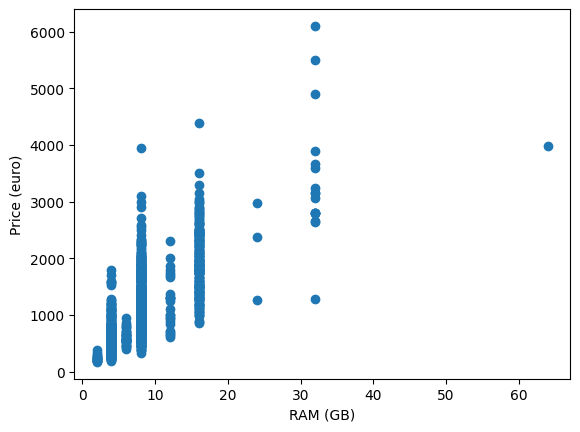

np.float64(0.7402865271622688)

In [14]:
import matplotlib.pyplot as plt
plt.xlabel("RAM (GB)")
plt.ylabel("Price (euro)")
plt.scatter(laptops["RAM (GB)"],laptops["Price (Euro)"])
plt.show()
laptops["RAM (GB)"].corr(laptops["Price (Euro)"])

In the scatter plot, I can see that it looks like there is a positive correlation between price and RAM. Laptops with more RAM usually have higher prices. We can see that some 32 GB RAM laptops have higher prices than the 64 GB RAM laptop. That's interesting, and we will need to investigate it further. Also, I can see a strong correlation between price and RAM of 0.74.

This information is important for someone who is looking to buy a computer because it can tell them what they get in terms of RAM for the price they pay.

Now I would like to see if there is a connection between the screen size (in inches) and the weight using a scatter plot and a calculation of the correlation.

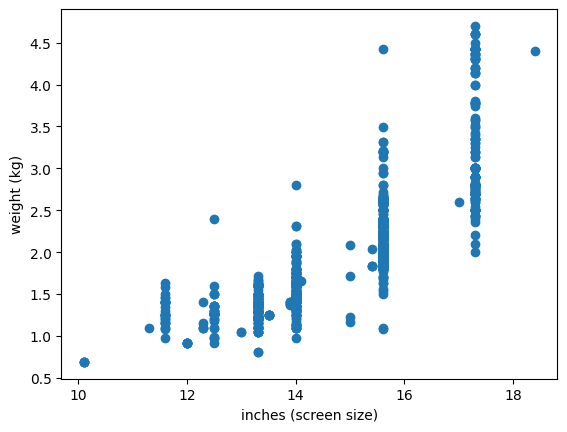

np.float64(0.8266379625499112)

In [15]:
plt.xlabel("inches (screen size)")
plt.ylabel("weight (kg)")
plt.scatter(laptops["Inches"], laptops["Weight (kg)"])
plt.show()
laptops["Inches"].corr(laptops["Weight (kg)"])

It looks like there is a positive correlation of 0.83 between the screen size (in inches) and the weight of the laptop.
This question is important for someone who wants to buy a computer because it allows them to find the balance between weight and screen size.

Now I would like to check which company has the priciest laptops and which has the cheapest. First, I'll check which companies I have in my table.

In [16]:
laptops["Company"].value_counts()

Company
Dell         291
Lenovo       289
HP           268
Asus         152
Acer         101
MSI           54
Toshiba       48
Apple         21
Samsung        9
Mediacom       7
Razer          7
Microsoft      6
Vero           4
Xiaomi         4
Chuwi          3
Fujitsu        3
Google         3
LG             3
Huawei         2
Name: count, dtype: int64

Now I will find the average price of each company.

In [17]:
average_prices = laptops.groupby("Company")["Price (Euro)"].mean()
print(average_prices)

Company
Acer          633.464455
Apple        1564.198571
Asus         1123.829737
Chuwi         314.296667
Dell         1199.225120
Fujitsu       729.000000
Google       1677.666667
HP           1080.314664
Huawei       1424.000000
LG           2099.000000
Lenovo       1093.862215
MSI          1728.908148
Mediacom      295.000000
Microsoft    1612.308333
Razer        3346.142857
Samsung      1413.444444
Toshiba      1267.812500
Vero          217.425000
Xiaomi       1133.462500
Name: Price (Euro), dtype: float64


In [18]:
sorted_average_prices = average_prices.sort_values()

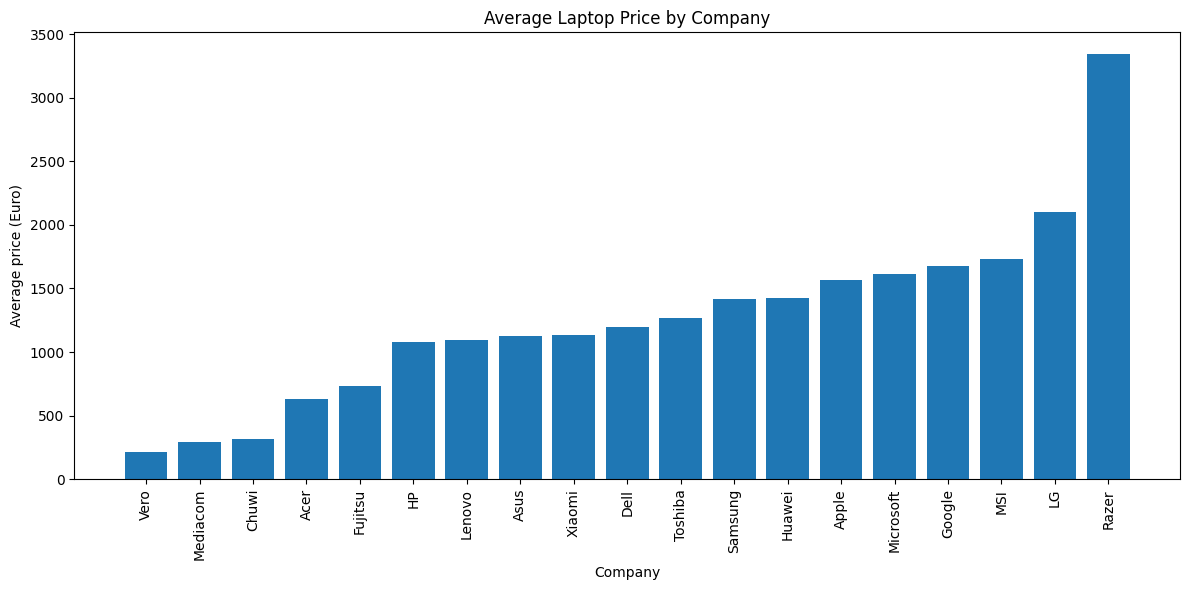

In [19]:
plt.figure(figsize=(12, 6))
plt.bar(sorted_average_prices.index, sorted_average_prices)
plt.xlabel("Company")
plt.ylabel("Average price (Euro)")
plt.title("Average Laptop Price by Company")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

I can clearly see that Vero has the lowest average price and Razer has the highest average price out of all the companies in the dataset. The bars together help me see which companies are pricier and which are cheaper on average.

This analysis is very important for someone who wants to buy a computer because it helps them understand which options might be cheaper.

## D. Investigate unusual observations



First, I want to identify potential outliers. I will use the IQR method (Interquartile Range method) on the price column and present it using a box plot.

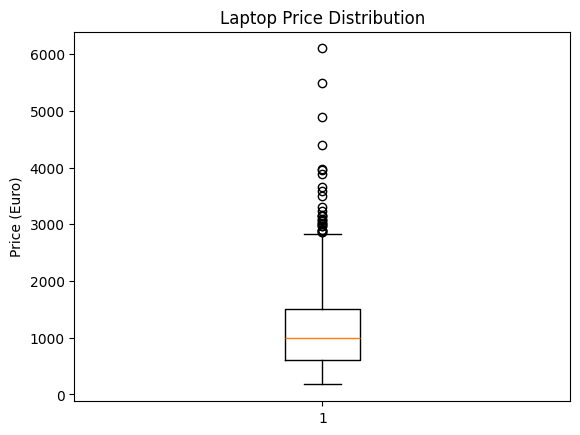

In [20]:
plt.boxplot(laptops["Price (Euro)"])
plt.ylabel("Price (Euro)")
plt.title("Laptop Price Distribution")
plt.show()

The box plot shows that there are indeed potential outliers in laptop prices.

Now we will calculate Q1, Q3, and the interquartile range (IQR), as well as the lower and upper limits for identifying potential outliers.

Potential outliers can be identified using Q1, Q3, and 1.5 times the IQR. The lower limit is Q1 minus 1.5 times the IQR, and the upper limit is Q3 plus 1.5 times the IQR.

In [21]:
q1 = laptops["Price (Euro)"].quantile(0.25)
q3 = laptops["Price (Euro)"].quantile(0.75)

iqr = q3 - q1

upper_limit = q3 + 1.5 * iqr
lower_limit = q1 - 1.5 * iqr

print("Q1 is" , q1, ",Q3 is", q3,",IQR is", iqr,",lower_limit", lower_limit,",upper_limit", upper_limit)

Q1 is 609.0 ,Q3 is 1496.5 ,IQR is 887.5 ,lower_limit -722.25 ,upper_limit 2827.75


Now I will check which laptops in the dataset have outlier prices. I will also check whether the outliers have unusually high or low prices.

In [22]:
high_prices = laptops[laptops["Price (Euro)"] > upper_limit]
low_prices = laptops[laptops["Price (Euro)"] < lower_limit]

print("High-price outliers:", len(high_prices))
print("Low-price outliers:", len(low_prices))

High-price outliers: 28
Low-price outliers: 0


I found 28 laptops with unusually high prices according to the IQR method, and no laptops with unusually low prices. This matches what I saw in the box plot.

Now I will check what the mean and median laptop prices are.

In [23]:
print("mean is" , laptops["Price (Euro)"].mean())
print("median is" , laptops["Price (Euro)"].median())

mean is 1134.9690588235292
median is 989.0


The mean is higher than the median, which suggests that high-priced laptops may be pulling the mean upward.

Now I will try to check whether the high-price outliers affect the median and the mean by calculating them using only the prices that are not outliers.

In [24]:
normal_prices = laptops[
    (laptops["Price (Euro)"] >= lower_limit) &
    (laptops["Price (Euro)"] <= upper_limit)
]

print("Mean without outliers:", normal_prices["Price (Euro)"].mean())
print("Median without outliers:", normal_prices["Price (Euro)"].median())

Mean without outliers: 1081.8476904570969
Median without outliers: 977.0


I can see that the median is now 12 euros lower and the mean is about 53 euros lower. This shows that the outliers affect both the median and the mean, but they affect the mean more (that makes sense because the median is less affected by extreme values).

I don't think we should remove the outliers. High-priced laptops can be real observations and may represent expensive laptop models. Without evidence that these prices are errors, I think we should keep them in the main analysis.

I will compare the results below and show an example.

In [25]:
print("mean is" , laptops["Price (Euro)"].mean())
print("median is" , laptops["Price (Euro)"].median())
normal_prices = laptops[
    (laptops["Price (Euro)"] >= lower_limit) &
    (laptops["Price (Euro)"] <= upper_limit)
]

print("Mean without outliers:", normal_prices["Price (Euro)"].mean())
print("Median without outliers:", normal_prices["Price (Euro)"].median())

mean is 1134.9690588235292
median is 989.0
Mean without outliers: 1081.8476904570969
Median without outliers: 977.0


We can see that the mean and median without outliers are lower.

Now I will see how removing the outliers affects one of my earlier price comparison bar charts.

Company
Acer          633.464455
Apple        1499.508500
Asus         1060.744054
Chuwi         314.296667
Dell         1129.471281
Fujitsu       729.000000
Google       1677.666667
HP           1042.374735
Huawei       1424.000000
LG           2099.000000
Lenovo       1051.835141
MSI          1728.908148
Mediacom      295.000000
Microsoft    1612.308333
Razer        1809.000000
Samsung      1413.444444
Toshiba      1267.812500
Vero          217.425000
Xiaomi       1133.462500
Name: Price (Euro), dtype: float64


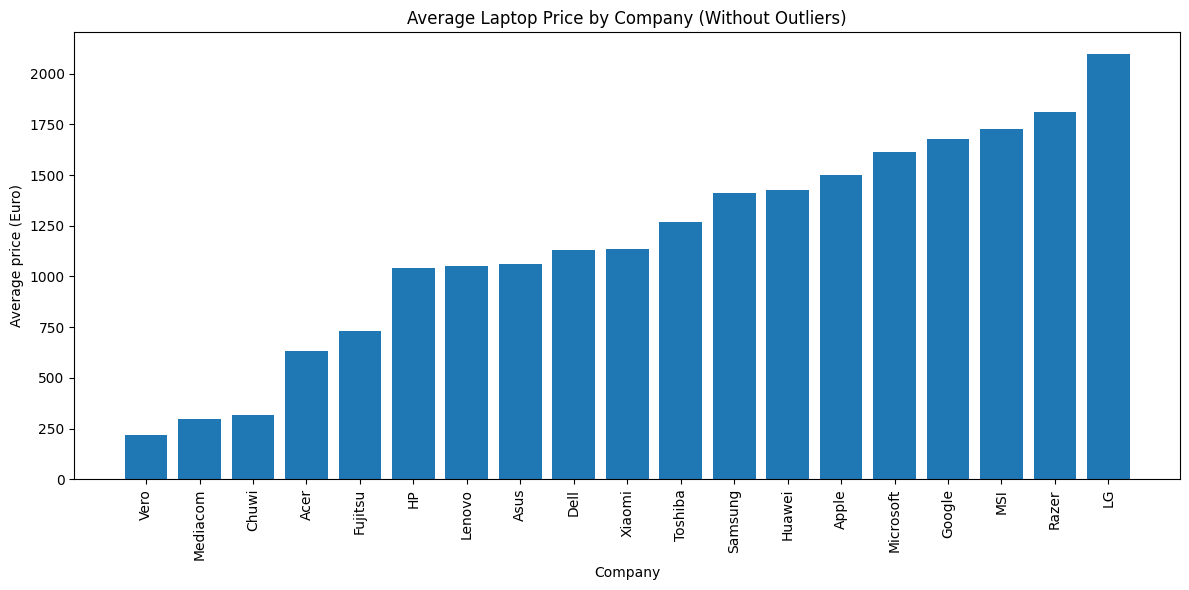

In [26]:
normal_average_prices = (normal_prices.groupby("Company")["Price (Euro)"].mean())
sorted_normal_average_prices = normal_average_prices.sort_values()
print(normal_average_prices)
plt.figure(figsize=(12, 6))
plt.bar(sorted_normal_average_prices.index, sorted_normal_average_prices)
plt.xlabel("Company")
plt.ylabel("Average price (Euro)")
plt.title("Average Laptop Price by Company (Without Outliers)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

The bar chart is showing me a very interesting fact. If I remove the outliers, the average price of Razer decreases considerably, and now it's even lower than LG's.

I think this shows us why we shouldn't remove outliers. A buyer should know that Razer has the highest average laptop price in our full dataset.

With that being said, some will say that the bar chart is actually showing us why we should remove outliers because, without them, we can understand that the average price of Razer is actually cheaper than LG's average price.

But there is also the number of laptops from each company to take into consideration.

In [27]:
print("before removing outliers", laptops["Company"].value_counts())
print("after removing outliers", normal_prices["Company"].value_counts())

before removing outliers Company
Dell         291
Lenovo       289
HP           268
Asus         152
Acer         101
MSI           54
Toshiba       48
Apple         21
Samsung        9
Mediacom       7
Razer          7
Microsoft      6
Vero           4
Xiaomi         4
Chuwi          3
Fujitsu        3
Google         3
LG             3
Huawei         2
Name: count, dtype: int64
after removing outliers Company
Lenovo       284
Dell         281
HP           264
Asus         148
Acer         101
MSI           54
Toshiba       48
Apple         20
Samsung        9
Mediacom       7
Microsoft      6
Vero           4
Xiaomi         4
Google         3
Chuwi          3
Razer          3
Fujitsu        3
LG             3
Huawei         2
Name: count, dtype: int64


We can see that if we remove the outliers, the number of Razer laptops in our data goes from 7 to 3. If we remove the outliers, we lose more than half of the data about Razer.

So, in conclusion, I do not think that we should remove the outliers in this case, mainly due to the fact that we don't know if the prices are false data or valid data. But the decision to remove the outliers depends on the data.

Now I would like to check if there are also potential outliers in the RAM column. This time, I will use Z-scores.

I will consider laptops with a RAM Z-score greater than 3 to be potential outliers.

In [28]:
ram_mean = laptops["RAM (GB)"].mean()
ram_std = laptops["RAM (GB)"].std()

ram_z = (laptops["RAM (GB)"] - ram_mean) / ram_std

print("RAM mean:", ram_mean)
print("RAM standard deviation:", ram_std)
print("RAM Z-scores above 3:")
high_ram_z=ram_z[ram_z > 3]

print(pd.DataFrame({
    "RAM (GB)": laptops["RAM (GB)"][ram_z > 3],
    "Z-score": high_ram_z
}))
print("Number of outliers:", len(high_ram_z))
upper_ram_limit = ram_mean + 3 * ram_std
print("Upper RAM limit:", upper_ram_limit)

RAM mean: 8.44078431372549
RAM standard deviation: 5.097809362352341
RAM Z-scores above 3:
      RAM (GB)    Z-score
177         32   4.621439
196         32   4.621439
238         32   4.621439
329         32   4.621439
438         24   3.052138
491         32   4.621439
494         24   3.052138
517         24   3.052138
577         32   4.621439
610         32   4.621439
650         32   4.621439
659         32   4.621439
723         32   4.621439
780         32   4.621439
830         32   4.621439
841         32   4.621439
901         32   4.621439
968         32   4.621439
972         32   4.621439
1066        64  10.898645
1081        32   4.621439
Number of outliers: 21
Upper RAM limit: 23.734212400782514


It seems like I have 21 outliers, with one very high Z-score of over 10. This laptop has 64 GB of RAM.

This seems high, but it can be a valid RAM size for a computer, so I don't think we should automatically eliminate those outliers either.

Also, from the scatter plot I made earlier of the correlation between RAM and price, it seems like pricier laptops tend to have more RAM.

Let's check this hypothesis by checking how many laptops have both a RAM outlier and a price outlier.

In [29]:
selected_laptops = laptops[
    (ram_z > 3) &
    (laptops["Price (Euro)"] > upper_limit)
]

print("There are", len(high_prices), "laptops with price outliers.")
print("There are", len(high_ram_z), "laptops with RAM outliers.")
print("There are", len(selected_laptops), "laptops with both RAM and price outliers.")

There are 28 laptops with price outliers.
There are 21 laptops with RAM outliers.
There are 12 laptops with both RAM and price outliers.


It seems like there is an association between RAM outliers and price outliers, since 12 laptops have both.

This strengthens the possibility that some of the outliers are valid observations of more expensive laptops with more RAM. However, it does not prove that their prices are correct, so I don't think we should eliminate them without evidence of an error.



## E. Scientific interpretation

### What I observed

I have found that there is a strong positive correlation between price and RAM (r = 0.74), and also a strong positive correlation between screen size (in inches) and weight (r = 0.83).

I have found that the company with the highest average price is Razer, and the company with the lowest average price is Vero.

I have found that there are 21 laptops with high RAM outliers and 28 laptops with high price outliers, and also that 12 laptops have both high price and high RAM outliers.

### What the analysis supports

The analysis supports the conclusion that laptops with more RAM are usually more expensive and that laptops with larger screens (in inches) are usually heavier.

The analysis also supports the conclusion that Vero is the company with the lowest average laptop price and Razer is the company with the highest average laptop price in our dataset.

The analysis of the outliers shows that removing them can change which company has the highest average laptop price. This supports the conclusion that removing outliers can change our results.

### What I cannot conclude

I cannot conclude whether the outliers are errors or valid data. Even though I have some evidence that the outliers may represent valid laptop prices or RAM values, I cannot be certain whether they are errors or valid observations.

I cannot conclude that Razer is the priciest company or that Vero is the cheapest in the overall market. Razer only has 7 laptops in our dataset, and only 3 remain if we eliminate the outliers. Vero only has 4 laptops in our dataset. The samples are too small to draw reliable conclusions about which companies are generally cheaper or more expensive.

I cannot conclude that there is a causal relationship between RAM and price or between screen size (in inches) and weight. All I can conclude about these relationships from my data is that there are correlations.